In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

master_df = pd.read_parquet(
    "../data/processed/master_df.parquet"
)

inventory = pd.read_parquet(
    "../data/processed/inventory_clean.parquet"
)

flags = pd.read_parquet(
    "../data/processed/flags_clean.parquet"
)

products = pd.read_parquet(
    "../data/processed/products_clean.parquet"
)

In [3]:
flags["flag"].value_counts()

flag
SLOW_MOVER       400
STOCKOUT_RISK    200
Name: count, dtype: int64

## Insight

The anomaly dataset contains two types of inventory issues:

- STOCKOUT_RISK: Products that may go out of stock.
- SLOW_MOVER: Products that are overstocked and sell slowly.

The company must minimize stockouts while also reducing excess inventory costs.

In [6]:
flagged_products = flags.merge(

    products,

    on="sku_id",

    how="left"
)

flagged_products.head()

,sku_id,flag,affected_stores,window_start,window_end,notes,sku_name,category,subcategory,unit_price,cost_price,brand
0,SKU04321,STOCKOUT_RISK,ST22;ST26;ST23;ST15;ST12;ST28;ST01;ST27;ST08;S...,2025-11-06,2025-12-03,Top-selling SKU (by observed volume); injected...,EliteHome Hair Care Pack of 6,Personal Care,Hair Care,961.30,658.32,EliteHome
1,SKU04596,STOCKOUT_RISK,ST12;ST09;ST21;ST23;ST07;ST24;ST01;ST28;ST14;S...,2025-10-25,2025-11-06,Top-selling SKU (by observed volume); injected...,ValueChoice Eggs Pack of 6,Dairy & Bakery,Eggs,335.55,242.79,ValueChoice
2,SKU03727,STOCKOUT_RISK,ST19;ST14;ST28;ST29;ST02;ST07;ST17;ST08;ST05;ST16,2025-11-08,2025-11-29,Top-selling SKU (by observed volume); injected...,QuickBite Mobile Accessories 2kg,Electronics & Accessories,Mobile Accessories,1660.93,1291.18,QuickBite
3,SKU04154,STOCKOUT_RISK,ST15;ST03;ST30;ST09;ST24;ST19;ST28;ST02;ST07;S...,2025-11-12,2025-11-26,Top-selling SKU (by observed volume); injected...,TrueTaste Spices & Seasoning Medium,Grocery,Spices & Seasoning,351.77,224.67,TrueTaste
4,SKU00953,STOCKOUT_RISK,ST09;ST19;ST27;ST20;ST01;ST03;ST11;ST10;ST22;S...,2025-11-29,2025-12-25,Top-selling SKU (by observed volume); injected...,CityFresh Writing Instruments 250ml,Stationery & Office,Writing Instruments,273.99,178.24,CityFresh


# Inventory Risk Analysis

## 1. Distribution of Inventory Anomalies

### Insight

- The dataset contains **600 flagged products**, out of which:

  - **400 (66.67%)** are classified as **SLOW_MOVER**.
  - **200 (33.33%)** are classified as **STOCKOUT_RISK**.

- Slow-moving products are twice as common as stockout-risk products.

- Excess inventory is a bigger challenge for the company than stock shortages.

### Business Recommendation

- Launch promotional campaigns and bundle offers for slow-moving products.

- Reduce future procurement of slow-moving items.

- Prioritize inventory optimization to minimize storage costs.

In [8]:
risk_category = (

    flagged_products

    .groupby(["category", "flag"])

    .size()

    .unstack(fill_value=0)

)

risk_category

flag,SLOW_MOVER,STOCKOUT_RISK
category,,
Apparel & Footwear,33,12
Beverages,38,12
Dairy & Bakery,39,18
Electronics & Accessories,30,16
Frozen Foods,31,18
Grocery,31,16
Health & Wellness,37,15
Home & Kitchen,30,16
Home Care,31,19


<Figure size 1400x600 with 0 Axes>

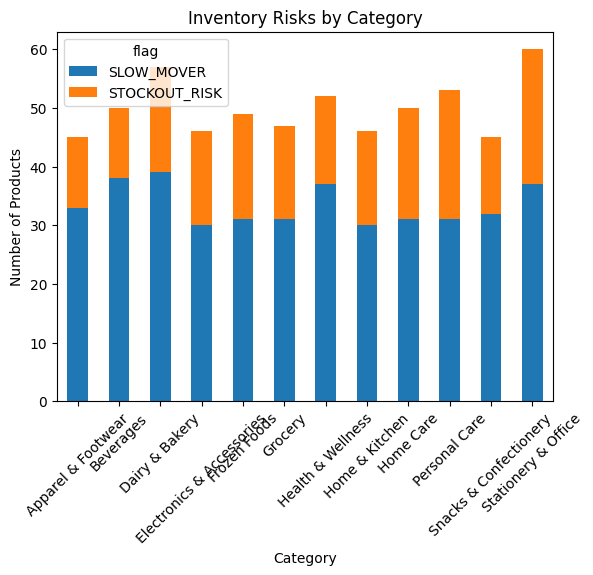

In [10]:
plt.figure(figsize=(14, 6))

risk_category.plot(
    kind="bar",
    stacked=True
)

plt.title("Inventory Risks by Category")

plt.xlabel("Category")

plt.ylabel("Number of Products")

plt.xticks(rotation=45)

plt.savefig(
    "../reports/images/inventory_risk_by_category.png",
    bbox_inches="tight"
)

plt.show()

# 2. Inventory Risk by Category

## Insight

- **Stationery & Office** has the highest total number of inventory issues (60 products).

- **Personal Care** has the highest number of stockout-risk products (22).

- **Home Care** and **Stationery & Office** are also heavily affected by stockouts.

- Categories such as **Beverages** and **Dairy & Bakery** contain a high number of slow-moving products.

## Business Recommendation

- Improve demand forecasting for Personal Care and Stationery products.

- Maintain additional safety stock for high-demand categories.

- Reduce inventory levels for categories with a high number of slow-moving products.

- Monitor category-wise inventory weekly to prevent losses.

In [13]:
inventory["stock_ratio"] = (

    inventory["stock_on_hand"]

    / inventory["reorder_point"]

)

inventory.head()

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,stock_ratio
0,ST11,SKU02558,323,72,22,2025-05-17,4.486111
1,ST21,SKU01031,236,67,14,2025-06-17,3.522388
2,ST26,SKU02129,433,96,34,2025-05-20,4.510417
3,ST19,SKU02907,178,34,13,2025-08-03,5.235294
4,ST05,SKU01023,333,97,22,2025-07-12,3.432990


In [15]:
inventory["risk_level"] = "Medium"

inventory.loc[

    inventory["stock_ratio"] < 1,

    "risk_level"

] = "High"

inventory.loc[

    inventory["stock_ratio"] > 3,

    "risk_level"

] = "Low"

In [17]:
inventory["risk_level"].value_counts()

risk_level
Low       9062
Medium    6365
High      5801
Name: count, dtype: int64

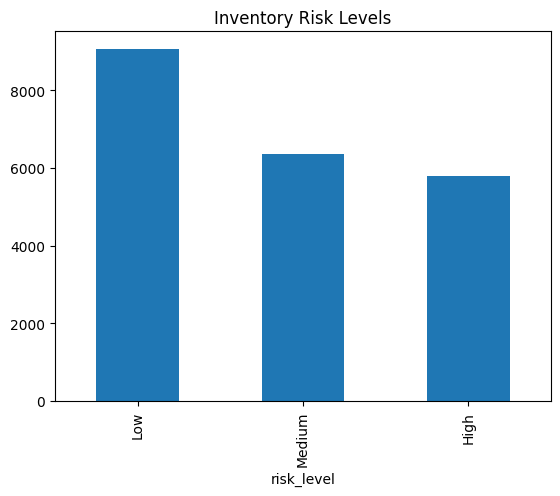

In [19]:
inventory["risk_level"].value_counts().plot(
    kind="bar"
)

plt.title("Inventory Risk Levels")

plt.savefig(
    "../reports/images/inventory_risk_levels.png",
    bbox_inches="tight"
)

plt.show()

# 3. Inventory Risk Levels

## Insight

Inventory has been classified into three categories:

- Low Risk: 9,062 products
- Medium Risk: 6,365 products
- High Risk: 5,801 products

Approximately 27% of products belong to the high-risk category.

Products with stock ratios below one are at immediate risk of stockouts.

## Business Recommendation

- Reorder products belonging to the high-risk category immediately.

- Set up automatic inventory alerts for products with stock ratios below one.

- Review reorder points and safety stock levels regularly.

In [22]:
high_risk = inventory[

    inventory["risk_level"] == "High"

]

top_risk = (

    high_risk

    .sort_values(

        by="stock_on_hand"

    )

    .head(20)

)

top_risk

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,stock_ratio,risk_level
222,ST29,SKU04710,0,51,13,2025-10-03,0.0,High
62,ST06,SKU04913,0,26,9,2025-09-09,0.0,High
63,ST04,SKU04315,0,76,24,2025-10-08,0.0,High
138,ST29,SKU04105,0,83,32,2025-09-25,0.0,High
140,ST06,SKU04350,0,92,26,2025-08-16,0.0,High
142,ST11,SKU00264,0,31,7,2025-08-21,0.0,High
146,ST05,SKU02930,0,23,8,2025-09-12,0.0,High
148,ST10,SKU00830,0,87,23,2025-08-31,0.0,High
154,ST16,SKU01547,0,79,26,2025-10-01,0.0,High
155,ST26,SKU00774,0,84,30,2025-09-27,0.0,High


# 4. High-Risk Products

## Insight

- Several products currently have zero stock while their reorder points are significantly higher.

- Multiple stores are at risk of losing sales because these products are unavailable.

- Products with zero stock can directly impact customer satisfaction and revenue.

## Business Recommendation

- Restock high-demand products immediately.

- Prioritize products with higher reorder points.

- Increase the frequency of inventory checks for critical SKUs.

- Build an automated replenishment system based on demand forecasting.

In [30]:
high_risk_skus = high_risk["sku_id"].unique()

revenue_risk = (

    master_df[master_df["sku_id"].isin(high_risk_skus)]

    .groupby("sku_id")["total_value"]

    .sum()

    .sort_values(ascending=False)

    .head(20)

)

revenue_risk

sku_id
SKU04321    1.066898e+09
SKU03727    2.614215e+08
SKU04329    9.468604e+07
SKU04596    8.894259e+07
SKU01371    8.408248e+07
SKU03053    8.407665e+07
SKU01189    7.029371e+07
SKU04551    6.920131e+07
SKU04157    6.910185e+07
SKU04571    6.249078e+07
SKU00994    5.385405e+07
SKU02692    5.205832e+07
SKU00728    5.075535e+07
SKU03323    5.012257e+07
SKU01363    5.009248e+07
SKU02833    4.651355e+07
SKU02141    4.457984e+07
SKU04154    4.269980e+07
SKU00531    3.905582e+07
SKU02368    3.209433e+07
Name: total_value, dtype: float64

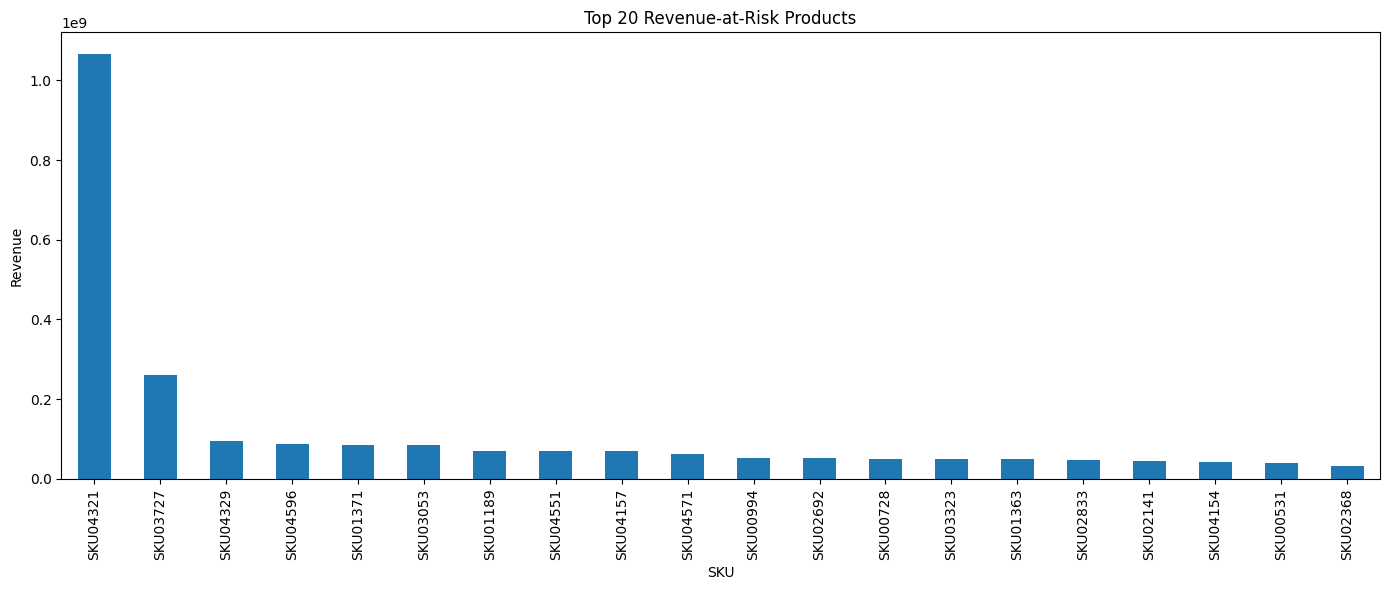

In [32]:
plt.figure(figsize=(14, 6))

revenue_risk.plot(kind="bar")

plt.title("Top 20 Revenue-at-Risk Products")

plt.xlabel("SKU")

plt.ylabel("Revenue")

plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    "../reports/images/revenue_at_risk.png",
    bbox_inches="tight"
)

plt.show()

# 5. Revenue-at-Risk Analysis

## Insight

- SKU04321 is the most critical product in the inventory, with approximately **1.07 billion** in revenue at risk.

- The revenue at risk for SKU04321 is almost **four times higher** than the second-ranked product (SKU03727), which contributes approximately **261 million**.

- A small number of products contribute disproportionately to the company's revenue, indicating a strong dependency on a few high-performing SKUs.

- The top 20 high-risk products together represent a significant portion of the company's total revenue.

- Any stockout affecting these products could result in substantial financial losses and negatively impact customer satisfaction.

- The distribution follows the **Pareto principle (80/20 rule)**, where a small percentage of products contribute to a large percentage of revenue.

---

## Business Recommendations

- Prioritize inventory replenishment for SKU04321 and other top revenue-generating products.

- Increase safety stock levels for high-revenue SKUs to prevent stockouts.

- Implement automated alerts whenever stock levels approach reorder points.

- Monitor high-risk products daily instead of weekly.

- Develop demand forecasting models specifically for the top 20 revenue-at-risk products.

- Diversify product sales to reduce dependency on a small number of SKUs.

- Allocate warehouse space and logistics resources preferentially to critical products.

---

## Business Impact

If the company fails to replenish these products on time, it could face:

- Revenue loss
- Reduced customer satisfaction
- Loss of customer loyalty
- Supply-chain disruptions
- Negative impact on future sales

In [35]:
top20_risk_revenue = revenue_risk.sum()

total_revenue = master_df["total_value"].sum()

risk_percentage = (

    top20_risk_revenue / total_revenue

) * 100

print(f"Revenue at risk: {risk_percentage:.2f}%")

Revenue at risk: 22.13%


In [37]:
sku_4321_revenue = revenue_risk.iloc[0]

sku_4321_percentage = (

    sku_4321_revenue / total_revenue

) * 100

print(

    f"SKU04321 contributes "

    f"{sku_4321_percentage:.2f}% "

    f"of total revenue."

)

SKU04321 contributes 9.79% of total revenue.


# 6. Revenue Impact Analysis

## Key Findings

- The top 20 high-risk products account for approximately **22.13% of the company's total revenue**.

- Nearly one-fourth of the company's revenue is exposed to inventory-related risks.

- SKU04321 alone contributes approximately **9.79% of the total revenue**, making it the most business-critical product.

- The company is highly dependent on a small number of products, increasing operational and financial risk.

- Any stockout involving SKU04321 could significantly impact overall business performance.

---

## Business Insights

- Inventory management failures affecting the top 20 products could put more than **22% of total revenue at risk**.

- The company should prioritize inventory planning for products with high revenue contributions.

- SKU04321 should be continuously monitored because even a short-term stockout could lead to substantial financial losses.

- The revenue distribution follows the Pareto principle, where a small fraction of products contributes a disproportionately large share of revenue.

---

## Recommendations

- Increase the safety stock level for SKU04321 and other critical products.

- Set up automated low-stock alerts for high-revenue SKUs.

- Improve demand forecasting for top-performing products.

- Conduct weekly inventory audits for the top 20 revenue-generating products.

- Reduce dependence on a single product by promoting alternative products.

---

## Conclusion

Inventory optimization is essential for business sustainability. By proactively managing high-risk products, the company can protect more than **22% of its revenue** and improve customer satisfaction.